In [1]:
!pip -q install "transformers>=4.40,<5" medmnist scipy

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
# ===== 1. Imports, configuration, Drive checkpointing =====
import os, json, math, random, time, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.stats import norm, beta

PROFILE = "smoke"   # "smoke" (fastest, real run) | "quick" | "full"

PROFILES = {
    "smoke": dict(n_train=900,  epochs=2, sigmas=[0.5],       eps_list=[0.5],             n_cert=45,  n0=16, n=100, n_atk=27,  atk_steps=5,  eot=2, n_pred=32,  adv_steps=2, adv_eot=1),
    "quick": dict(n_train=3000, epochs=5, sigmas=[0.25, 0.5], eps_list=[0.25, 0.5, 1.0],  n_cert=108, n0=32, n=200, n_atk=63,  atk_steps=10, eot=4, n_pred=64,  adv_steps=3, adv_eot=1),
    "full":  dict(n_train=9000, epochs=8, sigmas=[0.25, 0.5], eps_list=[0.25, 0.5, 1.0],  n_cert=270, n0=64, n=500, n_atk=135, atk_steps=20, eot=8, n_pred=100, adv_steps=5, adv_eot=2),
}
CFG = dict(PROFILES[PROFILE])
CFG.update(lr=1e-3, bs=64, n_ctx=8, alpha=1e-3, eps_train_mult=1.0, seed=0, atk_step_mult=2.5)
CERT_RADII = [0.0, 0.25, 0.5, 0.75, 1.0]
METHODS = ["zero-shot", "coop", "promptsmooth", "adv-promptsmooth"]
PRETTY = {"zero-shot": "Zero-shot", "coop": "CoOp (clean)", "promptsmooth": "PromptSmooth (base paper)", "adv-promptsmooth": "Adv-PromptSmooth (ours)"}

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = dev.type == "cuda"
if not USE_AMP:
    print("WARNING: no GPU detected. Switch to a T4 runtime (Runtime > Change runtime type); CPU will be far too slow.")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(CFG["seed"])

# ---- Google Drive (falls back to local, non-persistent storage) ----
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/medvlm_adaptive_smoothing"
except Exception as e:
    print("Drive not mounted (%s) -> using /content (NOT persistent across sessions)" % type(e).__name__)
    ROOT = "/content/medvlm_adaptive_smoothing"
RUN = f"{ROOT}/{PROFILE}"
os.makedirs(RUN, exist_ok=True)

def _py(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if torch.is_tensor(o): return o.tolist()
    raise TypeError(type(o))

def save_json(path, obj):
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=1, default=_py)
    os.replace(tmp, path)

def load_json(path):
    with open(path) as f:
        return json.load(f)

def save_torch(path, obj):
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)

save_json(f"{RUN}/config.json", dict(PROFILE=PROFILE, **CFG))
print("profile:", PROFILE, "| device:", dev, "| checkpoints ->", RUN)

Mounted at /content/drive
profile: smoke | device: cuda | checkpoints -> /content/drive/MyDrive/medvlm_adaptive_smoothing/smoke


In [3]:
# ===== 2. Data: PathMNIST (train from NCT-CRC-HE-100K, test from CRC-VAL-HE-7K) =====
import medmnist
from medmnist import INFO

DATA_DIR = "/content/medmnist"; os.makedirs(DATA_DIR, exist_ok=True)
info = INFO["pathmnist"]
DataClass = getattr(medmnist, info["python_class"])
SIZE = 64
try:
    ds_tr = DataClass(split="train", download=True, size=SIZE, root=DATA_DIR)
    ds_te = DataClass(split="test",  download=True, size=SIZE, root=DATA_DIR)
except Exception as e:
    print("size=%d failed (%s); falling back to 28x28 (weaker accuracy expected)" % (SIZE, e))
    SIZE = 28
    ds_tr = DataClass(split="train", download=True, size=SIZE, root=DATA_DIR)
    ds_te = DataClass(split="test",  download=True, size=SIZE, root=DATA_DIR)

CLASSNAMES = [info["label"][str(i)] for i in range(len(info["label"]))]
NCLS = len(CLASSNAMES)
print("classes:", CLASSNAMES, "| image size:", SIZE)

def stratified_idx(labels, n, seed):
    rng = np.random.RandomState(seed)
    labels = np.asarray(labels).ravel()
    per = max(1, n // len(np.unique(labels)))
    idx = []
    for c in np.unique(labels):
        ids = np.where(labels == c)[0]
        idx += list(rng.choice(ids, min(per, len(ids)), replace=False))
    idx = np.array(idx); rng.shuffle(idx)
    return idx

def to_t(imgs):
    return torch.from_numpy(np.ascontiguousarray(imgs)).permute(0, 3, 1, 2).float().div(255.0)

tr_idx = stratified_idx(ds_tr.labels, CFG["n_train"], seed=1)
te_idx = stratified_idx(ds_te.labels, CFG["n_cert"], seed=2)
Xtr = to_t(ds_tr.imgs[tr_idx]).to(dev); ytr = torch.from_numpy(ds_tr.labels.ravel()[tr_idx]).long().to(dev)
Xte = to_t(ds_te.imgs[te_idx]).to(dev); yte = torch.from_numpy(ds_te.labels.ravel()[te_idx]).long().to(dev)
print("train subset:", tuple(Xtr.shape), "| test subset:", tuple(Xte.shape))

100%|██████████| 1.07G/1.07G [07:22<00:00, 2.42MB/s]


classes: ['adipose', 'background', 'debris', 'lymphocytes', 'mucus', 'smooth muscle', 'normal colon mucosa', 'cancer-associated stroma', 'colorectal adenocarcinoma epithelium'] | image size: 64
train subset: (900, 3, 64, 64) | test subset: (45, 3, 64, 64)


In [4]:
# ===== 3. Frozen medical VLM (PLIP) + CoOp-style learnable prompt =====
from transformers import CLIPModel, AutoTokenizer

MODEL_ID = "vinid/plip"
try:
    clip = CLIPModel.from_pretrained(MODEL_ID)
except Exception as e:
    print("Could not load %s (%s). Falling back to generic CLIP ViT-B/32 (NOT a medical model)." % (MODEL_ID, e))
    MODEL_ID = "openai/clip-vit-base-patch32"
    clip = CLIPModel.from_pretrained(MODEL_ID)
clip = clip.to(dev).eval()
for p in clip.parameters():
    p.requires_grad_(False)
# Fast tokenizer (the slow CLIPTokenizer needs vocab.json, which the PLIP repo does not provide).
# PLIP was fine-tuned from OpenAI CLIP ViT-B/32 and uses the same BPE vocabulary, so the fallback is equivalent.
try:
    tok = AutoTokenizer.from_pretrained(MODEL_ID)
    _t = tok(["test"], padding="max_length", max_length=77, truncation=True, return_tensors="pt").input_ids
    assert _t.shape[1] == 77
except Exception as e:
    print("Tokenizer for %s unavailable (%s: %s); using openai/clip-vit-base-patch32 tokenizer." % (MODEL_ID, type(e).__name__, str(e)[:80]))
    tok = AutoTokenizer.from_pretrained("openai/clip-vit-base-patch32")
print("backbone:", MODEL_ID)

MEAN = torch.tensor([0.48145466, 0.4578275, 0.40821073], device=dev).view(1, 3, 1, 1)
STD  = torch.tensor([0.26862954, 0.26130258, 0.27577711], device=dev).view(1, 3, 1, 1)
SCALE = min(float(clip.logit_scale.exp()), 100.0)

def img_feats(x):
    # x: [B,3,H,W] in pixel space ([0,1] for clean images; may be unbounded after adding noise)
    x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False)
    x = (x - MEAN) / STD
    with torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=USE_AMP):
        f = clip.get_image_features(pixel_values=x)
    return F.normalize(f.float(), dim=-1)

@torch.no_grad()
def img_feats_nograd(x, chunk=256):
    return torch.cat([img_feats(x[i:i + chunk]) for i in range(0, x.shape[0], chunk)])

# One global forward hook on the token embedding injects the learnable context (version-robust: no private HF APIs).
CTX_STATE = {"ctx": None, "n_ctx": CFG["n_ctx"]}
def _inject_hook(module, args, out):
    ctx = CTX_STATE["ctx"]
    if ctx is None:
        return None
    C, n = out.shape[0], CTX_STATE["n_ctx"]
    return torch.cat([out[:, :1], ctx.unsqueeze(0).expand(C, -1, -1).to(out.dtype), out[:, 1 + n:]], dim=1)
if "_hook" in globals():
    _hook.remove()
_hook = clip.text_model.embeddings.token_embedding.register_forward_hook(_inject_hook)

class PromptLearner(nn.Module):
    # "[SOS] X X ... X <classname> . [EOS]" with the n_ctx 'X' embeddings replaced by trainable vectors.
    def __init__(self, n_ctx=CFG["n_ctx"], init_text="a high quality H&E image of"):
        super().__init__()
        prompts = [" ".join(["X"] * n_ctx) + " " + c + "." for c in CLASSNAMES]
        self.ids = tok(prompts, padding="max_length", max_length=77, truncation=True, return_tensors="pt").input_ids.to(dev)
        with torch.no_grad():
            init_ids = tok(init_text, return_tensors="pt").input_ids[0].to(dev)[1:-1][:n_ctx]
            e = clip.text_model.embeddings.token_embedding(init_ids)
            ctx = torch.randn(n_ctx, e.shape[1], device=dev) * 0.02
            ctx[:e.shape[0]] = e
        self.ctx = nn.Parameter(ctx)

    def text_feats(self):
        CTX_STATE["ctx"] = self.ctx
        try:
            with torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=USE_AMP):
                t = clip.get_text_features(input_ids=self.ids)
        finally:
            CTX_STATE["ctx"] = None
        return F.normalize(t.float(), dim=-1)

@torch.no_grad()
def zero_shot_T(templates=("a histopathology image of {}.", "an H&E stained image of {}.", "a pathology patch showing {}.")):
    feats = []
    for t in templates:
        ids = tok([t.format(c) for c in CLASSNAMES], padding="max_length", max_length=77, truncation=True, return_tensors="pt").input_ids.to(dev)
        with torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=USE_AMP):
            f = clip.get_text_features(input_ids=ids)
        feats.append(F.normalize(f.float(), dim=-1))
    return F.normalize(torch.stack(feats).mean(0), dim=-1)

# quick sanity check: clean zero-shot accuracy of the frozen backbone
T_zs = zero_shot_T()
with torch.no_grad():
    clean_zs_acc = ((SCALE * img_feats_nograd(Xte) @ T_zs.t()).argmax(1) == yte).float().mean().item()
print("zero-shot CLEAN accuracy on test subset: %.1f%%  (chance = %.1f%%)" % (100 * clean_zs_acc, 100 / NCLS))

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/568 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

backbone: vinid/plip
zero-shot CLEAN accuracy on test subset: 64.4%  (chance = 11.1%)


In [5]:
# ===== 4. Randomized smoothing: certification (Cohen et al. 2019) and smoothed prediction =====
def cp_lower(k, n, alpha):
    # one-sided Clopper-Pearson lower bound on a binomial proportion (k successes out of n)
    k = np.asarray(k, dtype=float)
    return np.where(k <= 0, 0.0, beta.ppf(alpha, np.maximum(k, 1.0), n - k + 1.0))

def wilson(k, n, z=1.96):
    if n == 0: return (0.0, 0.0)
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n)
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return ((c - h) / d, (c + h) / d)

@torch.no_grad()
def cache_cert_feats(sigma, n_total):
    # Noisy image features for every test image: [N, n0+n, D] (fp16, CPU). The encoder is frozen, so
    # these are shared by ALL methods (common random numbers) -> certification of every method is nearly free.
    g = torch.Generator(device=dev).manual_seed(int(sigma * 1000) + 7)
    N = Xte.shape[0]
    out = torch.empty(N, n_total, clip.config.projection_dim, dtype=torch.float16)
    for i in range(N):
        x = Xte[i:i + 1].expand(n_total, -1, -1, -1)
        noise = torch.randn(x.shape, generator=g, device=dev) * sigma
        out[i] = img_feats_nograd(x + noise).half().cpu()
    return out

@torch.no_grad()
def certify_all(feats, y, T, sigma, n0, alpha):
    f = feats.to(dev).float()
    lg = SCALE * torch.einsum("nmd,cd->nmc", f, T)
    pred = lg.argmax(-1)                                   # [N, M]
    oh = F.one_hot(pred, T.shape[0])                       # [N, M, C]
    cA = oh[:, :n0].sum(1).argmax(1)                       # class guessed from the selection samples
    cnt = oh[:, n0:].sum(1).gather(1, cA[:, None]).squeeze(1).cpu().numpy()
    n = pred.shape[1] - n0
    pA = cp_lower(cnt, n, alpha)
    radius = np.where(pA > 0.5, sigma * norm.ppf(np.clip(pA, 0.5 + 1e-12, 1 - 1e-12)), -1.0)   # -1 => abstain
    cA = cA.cpu().numpy()
    smoothed_acc = float((oh.sum(1).argmax(1).cpu().numpy() == y.cpu().numpy()).mean())
    return dict(cA=cA.tolist(), radius=radius.tolist(), correct=(cA == y.cpu().numpy()).tolist(), smoothed_acc=smoothed_acc)

def cert_acc(res, r):
    rad = np.array(res["radius"]); cor = np.array(res["correct"])
    return float(np.mean(cor & (rad >= r)))

@torch.no_grad()
def smoothed_predict(x, T, sigma, n_pred, alpha):
    # Monte-Carlo smoothed prediction with an abstention rule (CP lower bound <= 0.5 -> abstain)
    B, C = x.shape[0], T.shape[0]
    counts = torch.zeros(B, C, device=dev)
    d = max(1, 512 // B)
    for s in range(0, n_pred, d):
        m = min(d, n_pred - s)
        xr = x.unsqueeze(1).expand(B, m, *x.shape[1:]).reshape(B * m, *x.shape[1:])
        f = img_feats_nograd(xr + sigma * torch.randn_like(xr))
        p = (SCALE * f @ T.t()).argmax(-1).view(B, m)
        counts += F.one_hot(p, C).sum(1)
    pred = counts.argmax(1)
    k = counts.max(1).values.cpu().numpy()
    abstain = cp_lower(k, n_pred, alpha) <= 0.5
    return pred.cpu().numpy(), abstain

# ---- unit test of the statistics (no GPU needed) ----
assert abs(cp_lower(np.array([100]), 100, 1e-3)[0] - 1e-3 ** (1 / 100)) < 1e-6      # all-correct case has a closed form
assert cp_lower(np.array([0]), 50, 1e-3)[0] == 0.0
assert 0.39 < wilson(50, 100)[0] < 0.5 < wilson(50, 100)[1] < 0.61
print("smoothing utilities: unit tests passed")

smoothing utilities: unit tests passed


In [6]:
# ===== 5. Attacks: PGD-L2 on the base classifier (A1, defense-unaware) and EOT-PGD on the smoothed classifier (A2, defense-aware) =====
def pgd_l2_smooth(x, y, T, sigma, eps, steps, m, step_mult=CFG["atk_step_mult"]):
    # m == 0 : attack the noise-free base classifier f_theta                       (A1, defense-unaware)
    # m  > 0 : maximise -log of the m-sample-average softmax under fresh Gaussian noise  (A2, defense-aware / EOT)
    T = T.detach()
    delta = torch.zeros_like(x)
    alpha_step = step_mult * eps / steps
    with torch.enable_grad():
        for _ in range(steps):
            delta.requires_grad_(True)
            xa = (x + delta).clamp(0, 1)
            if m > 0:
                B = x.shape[0]
                xr = xa.unsqueeze(1).expand(B, m, *xa.shape[1:]).reshape(B * m, *xa.shape[1:])
                f = img_feats(xr + sigma * torch.randn_like(xr))
                p = F.softmax(SCALE * f @ T.t(), dim=-1).view(B, m, -1).mean(1)
                loss = -torch.log(p.gather(1, y[:, None]).squeeze(1) + 1e-12)
            else:
                loss = F.cross_entropy(SCALE * img_feats(xa) @ T.t(), y, reduction="none")
            # x1024: only rescales the gradient (we normalise it below) but avoids fp16 underflow under autocast
            g, = torch.autograd.grad(loss.sum() * 1024.0, delta)
            g = torch.nan_to_num(g)
            gn = g.flatten(1).norm(dim=1).clamp_min(1e-12).view(-1, 1, 1, 1)
            delta = delta.detach() + alpha_step * g / gn
            dn = delta.flatten(1).norm(dim=1).clamp_min(1e-12).view(-1, 1, 1, 1)
            delta = delta * torch.clamp(eps / dn, max=1.0)             # project onto the L2 ball
            delta = ((x + delta).clamp(0, 1) - x).detach()              # keep a valid image (only shrinks the norm)
    return (x + delta).detach()

def attack_batched(x, y, T, sigma, eps, steps, m):
    ab = max(1, 256 // m) if m > 0 else 128
    return torch.cat([pgd_l2_smooth(x[i:i + ab], y[i:i + ab], T, sigma, eps, steps, m) for i in range(0, x.shape[0], ab)])

In [7]:
# ===== 6. Prompt training: CoOp (clean) | PromptSmooth (noise-aug; base paper) | Adv-PromptSmooth (ours) =====
def train_prompt(mode, sigma, log_prefix=""):
    # Identical init / optimizer / epochs / seed for all modes; the ONLY difference is how training inputs are built:
    #   coop         : clean image features
    #   promptsmooth : x + N(0, sigma^2 I)
    #   adv          : (x + delta*) + N(0, sigma^2 I), delta* = EOT-PGD-L2 against the current prompt (eps_train = mult * sigma)
    set_seed(123)
    pl = PromptLearner()
    opt = torch.optim.Adam(pl.parameters(), lr=CFG["lr"])
    N, bs = Xtr.shape[0], CFG["bs"]
    steps_per = math.ceil(N / bs); total = steps_per * CFG["epochs"]
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=total)
    eps_train = CFG["eps_train_mult"] * sigma
    Fclean = img_feats_nograd(Xtr) if mode == "coop" else None
    log = []
    for ep in range(CFG["epochs"]):
        perm = torch.randperm(N, device=dev); tl = 0.0; tc = 0
        for s in range(steps_per):
            idx = perm[s * bs:(s + 1) * bs]; x, y = Xtr[idx], ytr[idx]
            T = pl.text_feats()
            if mode == "coop":
                f = Fclean[idx]
            else:
                if mode == "adv":
                    x = pgd_l2_smooth(x, y, T.detach(), sigma, eps_train, CFG["adv_steps"], CFG["adv_eot"])
                f = img_feats_nograd(x + sigma * torch.randn_like(x))
            logits = SCALE * f @ T.t()
            loss = F.cross_entropy(logits, y)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
            tl += loss.item() * len(idx); tc += (logits.argmax(1) == y).sum().item()
        log.append(dict(epoch=ep + 1, loss=tl / N, train_acc=tc / N))
        print(f"{log_prefix}[{mode:>12s} sigma={sigma}] epoch {ep + 1}/{CFG['epochs']}  loss {tl / N:.3f}  train-acc(on its own inputs) {tc / N:.3f}")
    return pl, log

def get_T(method, sigma):
    if method == "zero-shot":
        return zero_shot_T()
    mode = {"coop": "coop", "promptsmooth": "promptsmooth", "adv-promptsmooth": "adv"}[method]
    # CoOp's prompt does not depend on sigma; still stored per sigma for simplicity
    path = f"{RUN}/prompt_{method}_s{sigma}.pt"
    pl = PromptLearner()
    if os.path.exists(path):
        pl.ctx.data = torch.load(path, map_location=dev)["ctx"].to(dev)
        print("loaded checkpoint:", os.path.basename(path))
    else:
        t0 = time.time()
        pl, log = train_prompt(mode, sigma)
        save_torch(path, dict(ctx=pl.ctx.detach().cpu(), log=log, train_seconds=time.time() - t0))
        print("saved checkpoint:", os.path.basename(path), "(%.0fs)" % (time.time() - t0))
    with torch.no_grad():
        return pl.text_feats().detach()

In [11]:
# ===== 7. Train all prompts, certify all methods (REPRODUCTION of the base paper's certified-accuracy comparison) =====
TS, CERT = {}, {}
n_total = CFG["n0"] + CFG["n"]
t_start = time.time()
for sigma in CFG["sigmas"]:
    fpath = f"{RUN}/certfeats_s{sigma}.pt"
    if os.path.exists(fpath):
        feats = torch.load(fpath)
    else:
        feats = cache_cert_feats(sigma, n_total); save_torch(fpath, feats)
    for method in METHODS:
        TS[(method, sigma)] = get_T(method, sigma)
        CERT[(method, sigma)] = certify_all(feats, yte, TS[(method, sigma)], sigma, CFG["n0"], CFG["alpha"])
    del feats
save_json(f"{RUN}/cert_results.json", {f"{m}|{s}": v for (m, s), v in CERT.items()})
print("training + certification stage done in %.0fs" % (time.time() - t_start))

rows = []
for (m, s), res in CERT.items():
    row = {"sigma": s, "method": PRETTY[m], "smoothed clean acc": 100 * res["smoothed_acc"],
           "abstain %": 100 * float(np.mean(np.array(res["radius"]) < 0))}
    for r in CERT_RADII:
        row[f"cert acc @ r={r}"] = 100 * cert_acc(res, r)
    rows.append(row)
df_cert = pd.DataFrame(rows).sort_values(["sigma", "method"]).reset_index(drop=True)
df_cert.to_csv(f"{RUN}/table1_certified_accuracy.csv", index=False)
print("\nTABLE 1 - certified accuracy (%%) on PathMNIST-test subset (n=%d, alpha=%g)" % (Xte.shape[0], CFG["alpha"]))
display(df_cert.round(1))

print("\nReference (as quoted in the SLR for the ORIGINAL paper; different datasets/resolution/radius scale -> NOT directly comparable):")
display(pd.DataFrame([
    dict(setting="PLIP / KatherColon, r=1.5", PromptSmooth="45.6%", DiffusionSmoothing="16.0%"),
    dict(setting="MedCLIP / COVID, r=0.75", PromptSmooth="52.6%", DiffusionSmoothing="n/a in SLR"),
    dict(setting="MedCLIP / RSNA Pneumonia, r=0.75", PromptSmooth="32.0%", DiffusionSmoothing="n/a in SLR"),
]))

# ---- automatic reproduction check: does prompt learning under noise beat zero-shot and clean-CoOp? ----
print("\nREPRODUCTION CHECK (qualitative claim: noise-trained prompts > zero-shot and clean-trained prompts)")
repro = []
for s in CFG["sigmas"]:
    for r in [0.0, 0.25, 0.5]:
        ps, zs, co = (cert_acc(CERT[(m, s)], r) for m in ("promptsmooth", "zero-shot", "coop"))
        ok = ps > zs and ps > co
        if ps == zs == co == 0: ok = None   # radius not reachable at this sigma / n
        repro.append(dict(sigma=s, radius=r, promptsmooth=100 * ps, zero_shot=100 * zs, coop=100 * co, supported=ok))
df_repro = pd.DataFrame(repro); display(df_repro.round(1))
df_repro.to_csv(f"{RUN}/reproduction_check.csv", index=False)
valid = df_repro["supported"].dropna()
print("claim supported in %d/%d testable (sigma, radius) cells" % (int(valid.sum()), len(valid)))

loaded checkpoint: prompt_coop_s0.5.pt
loaded checkpoint: prompt_promptsmooth_s0.5.pt
loaded checkpoint: prompt_adv-promptsmooth_s0.5.pt
training + certification stage done in 0s

TABLE 1 - certified accuracy (%) on PathMNIST-test subset (n=45, alpha=0.001)


,sigma,method,smoothed clean acc,abstain %,cert acc @ r=0.0,cert acc @ r=0.25,cert acc @ r=0.5,cert acc @ r=0.75,cert acc @ r=1.0
0,0.5,Adv-PromptSmooth (ours),22.2,64.4,4.4,0.0,0.0,0.0,0.0
1,0.5,CoOp (clean),11.1,0.0,11.1,11.1,11.1,11.1,0.0
2,0.5,PromptSmooth (base paper),26.7,60.0,17.8,11.1,8.9,2.2,0.0
3,0.5,Zero-shot,11.1,0.0,11.1,11.1,11.1,11.1,0.0



Reference (as quoted in the SLR for the ORIGINAL paper; different datasets/resolution/radius scale -> NOT directly comparable):


,setting,PromptSmooth,DiffusionSmoothing
0,"PLIP / KatherColon, r=1.5",45.6%,16.0%
1,"MedCLIP / COVID, r=0.75",52.6%,n/a in SLR
2,"MedCLIP / RSNA Pneumonia, r=0.75",32.0%,n/a in SLR



REPRODUCTION CHECK (qualitative claim: noise-trained prompts > zero-shot and clean-trained prompts)


,sigma,radius,promptsmooth,zero_shot,coop,supported
0,0.5,0.0,17.8,11.1,11.1,True
1,0.5,0.2,11.1,11.1,11.1,False
2,0.5,0.5,8.9,11.1,11.1,False


claim supported in 1/3 testable (sigma, radius) cells


In [12]:
# ===== 8. Defense-unaware (A1) vs defense-aware (A2) attacks + certificate audit (resumable) =====
ATK_PATH = f"{RUN}/attack_rows.json"
ROWS = load_json(ATK_PATH) if os.path.exists(ATK_PATH) else []
done = {(r["method"], r["sigma"], r["eps"], r["attack"]) for r in ROWS}
n_atk = CFG["n_atk"]
xs, ys = Xte[:n_atk], yte[:n_atk]
y_np = ys.cpu().numpy()

def outcome_row(method, sigma, eps, attack, pred, abst, cert):
    correct = pred == y_np
    lo, hi = wilson(int(correct.sum()), n_atk)
    row = dict(method=method, sigma=sigma, eps=eps, attack=attack, n=n_atk,
               acc=float(correct.mean()), acc_lo=lo, acc_hi=hi,
               acc_confident=float((correct & ~abst).mean()), abstain=float(abst.mean()),
               wrong_confident=float((~correct & ~abst).mean()))
    if attack != "clean":
        rad = np.array(cert["radius"][:n_atk]); cor = np.array(cert["correct"][:n_atk])
        certified = cor & (rad >= eps)
        row.update(n_cert_at_eps=int(certified.sum()), flips_cert=int((certified & ~correct).sum()),
                   conf_flips_cert=int((certified & ~correct & ~abst).sum()))
    return row

t0 = time.time()
for sigma in CFG["sigmas"]:
    for method in METHODS:
        T, cert = TS[(method, sigma)], CERT[(method, sigma)]
        if (method, sigma, 0.0, "clean") not in done:
            set_seed(1000)
            pred, abst = smoothed_predict(xs, T, sigma, CFG["n_pred"], CFG["alpha"])
            ROWS.append(outcome_row(method, sigma, 0.0, "clean", pred, abst, cert))
        for eps in CFG["eps_list"]:
            for attack in ("naive", "adaptive"):
                if (method, sigma, eps, attack) in done:
                    continue
                set_seed(2000 + int(100 * eps))
                m = 0 if attack == "naive" else CFG["eot"]
                xa = attack_batched(xs, ys, T, sigma, eps, CFG["atk_steps"], m)
                l2 = (xa - xs).flatten(1).norm(dim=1).max().item()
                assert l2 <= eps + 1e-3, f"L2 budget violated: {l2} > {eps}"
                set_seed(3000)                                   # evaluation noise is independent of the attack's noise
                pred, abst = smoothed_predict(xa, T, sigma, CFG["n_pred"], CFG["alpha"])
                ROWS.append(outcome_row(method, sigma, eps, attack, pred, abst, cert))
            save_json(ATK_PATH, ROWS)                            # checkpoint after every (method, sigma, eps)
            done = {(r["method"], r["sigma"], r["eps"], r["attack"]) for r in ROWS}
            print("  done: sigma=%s eps=%s %-18s  (%.0fs elapsed)" % (sigma, eps, PRETTY[method], time.time() - t0))
save_json(ATK_PATH, ROWS)
print("attack stage finished in %.0fs" % (time.time() - t0))

  done: sigma=0.5 eps=0.5 Zero-shot           (4s elapsed)
  done: sigma=0.5 eps=0.5 CoOp (clean)        (7s elapsed)
  done: sigma=0.5 eps=0.5 PromptSmooth (base paper)  (11s elapsed)
  done: sigma=0.5 eps=0.5 Adv-PromptSmooth (ours)  (14s elapsed)
attack stage finished in 14s


TABLE 2 - smoothed-classifier accuracy (fractions, n=27 images) under defense-unaware (A1) and defense-aware (A2) L2 attacks


,sigma,eps,method,clean acc,A1 naive acc,A2 adaptive acc,A2 CI lo,A2 CI hi,overestimation gap (naive - adaptive),A2 abstain,A2 confidently wrong
0,0.5,0.5,Adv-PromptSmooth (ours),0.296,0.259,0.222,0.106,0.408,0.037,0.926,0.074
1,0.5,0.5,CoOp (clean),0.074,0.074,0.074,0.021,0.234,0.000,0.000,0.926
2,0.5,0.5,PromptSmooth (base paper),0.222,0.222,0.222,0.106,0.408,0.000,0.741,0.185
3,0.5,0.5,Zero-shot,0.074,0.074,0.074,0.021,0.234,0.000,0.000,0.926



TABLE 3 - certificate audit under the ADAPTIVE attack (images certified at radius >= eps)
flips = argmax changed (a few are expected from finite-sample noise near the boundary); conf_flips = wrong AND not abstained (should be ~0)


,sigma,eps,method,n_cert_at_eps,flips_cert,conf_flips_cert
0,0.5,0.5,Adv-PromptSmooth (ours),0.0,0.0,0.0
1,0.5,0.5,CoOp (clean),2.0,0.0,0.0
2,0.5,0.5,PromptSmooth (base paper),1.0,0.0,0.0
3,0.5,0.5,Zero-shot,2.0,0.0,0.0



HYPOTHESIS READ-OUT
H1 overestimation gap for PromptSmooth > 0 in 0/1 (sigma, eps) cells; mean gap 0.000
H2 Adv-PromptSmooth minus PromptSmooth, adaptive acc: mean +0.000 (higher in 0/1 cells); clean acc change: mean +0.074
   (with n=27 images per cell, differences within about +/-0.12 are inside the Wilson CIs - treat as inconclusive)
H3 audit: 5 certified (image, eps) instances; 0 argmax flips; 0 confident flips


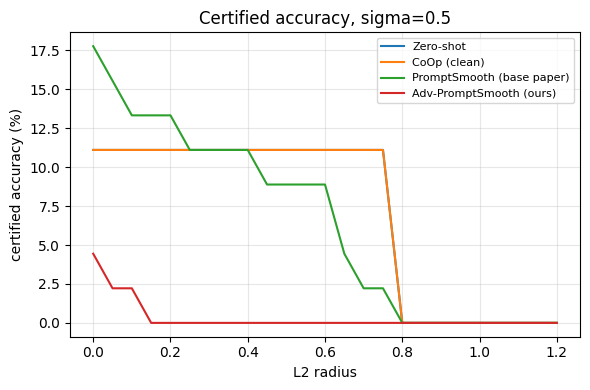

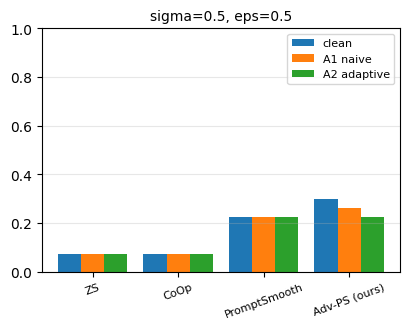


All artefacts saved to: /content/drive/MyDrive/medvlm_adaptive_smoothing/smoke
   attack_rows.json
   cert_results.json
   certfeats_s0.5.pt
   config.json
   fig1_certified_accuracy.png
   fig2_naive_vs_adaptive.png
   prompt_adv-promptsmooth_s0.5.pt
   prompt_coop_s0.5.pt
   prompt_promptsmooth_s0.5.pt
   reproduction_check.csv
   summary.json
   table1_certified_accuracy.csv
   table2_attack_results.csv
   table3_certificate_audit.csv


In [13]:
# ===== 9. Results: overestimation gap, Adv-PromptSmooth vs PromptSmooth, certificate audit, figures =====
df = pd.DataFrame(ROWS)
df["method"] = df["method"].map(PRETTY)
clean = df[df.attack == "clean"].set_index(["sigma", "method"])["acc"]
att = df[df.attack != "clean"]

piv = att.pivot_table(index=["sigma", "eps", "method"], columns="attack", values="acc").reset_index()
piv["clean acc"] = [clean[(s, m)] for s, m in zip(piv.sigma, piv.method)]
piv["overestimation gap (naive - adaptive)"] = piv["naive"] - piv["adaptive"]
extra = att[att.attack == "adaptive"].set_index(["sigma", "eps", "method"])[["acc_lo", "acc_hi", "abstain", "wrong_confident"]]
piv = piv.join(extra, on=["sigma", "eps", "method"])
piv = piv.rename(columns={"naive": "A1 naive acc", "adaptive": "A2 adaptive acc", "acc_lo": "A2 CI lo", "acc_hi": "A2 CI hi",
                          "abstain": "A2 abstain", "wrong_confident": "A2 confidently wrong"})
cols = ["sigma", "eps", "method", "clean acc", "A1 naive acc", "A2 adaptive acc", "A2 CI lo", "A2 CI hi",
        "overestimation gap (naive - adaptive)", "A2 abstain", "A2 confidently wrong"]
piv = piv[cols].sort_values(["sigma", "eps", "method"]).reset_index(drop=True)
piv.to_csv(f"{RUN}/table2_attack_results.csv", index=False)
print("TABLE 2 - smoothed-classifier accuracy (fractions, n=%d images) under defense-unaware (A1) and defense-aware (A2) L2 attacks" % n_atk)
display(piv.round(3))

audit = att[att.attack == "adaptive"][["sigma", "eps", "method", "n_cert_at_eps", "flips_cert", "conf_flips_cert"]]
audit = audit.sort_values(["sigma", "eps", "method"]).reset_index(drop=True)
audit.to_csv(f"{RUN}/table3_certificate_audit.csv", index=False)
print("\nTABLE 3 - certificate audit under the ADAPTIVE attack (images certified at radius >= eps)")
print("flips = argmax changed (a few are expected from finite-sample noise near the boundary); conf_flips = wrong AND not abstained (should be ~0)")
display(audit)

# ---- hypothesis read-out (reported as measured; no spin) ----
print("\nHYPOTHESIS READ-OUT")
ps = piv[piv.method == PRETTY["promptsmooth"]].set_index(["sigma", "eps"])
ad = piv[piv.method == PRETTY["adv-promptsmooth"]].set_index(["sigma", "eps"])
gap = ps["overestimation gap (naive - adaptive)"]
print("H1 overestimation gap for PromptSmooth > 0 in %d/%d (sigma, eps) cells; mean gap %.3f" % ((gap > 0).sum(), len(gap), gap.mean()))
d_adapt = (ad["A2 adaptive acc"] - ps["A2 adaptive acc"]); d_clean = (ad["clean acc"] - ps["clean acc"])
print("H2 Adv-PromptSmooth minus PromptSmooth, adaptive acc: mean %+.3f (higher in %d/%d cells); clean acc change: mean %+.3f"
      % (d_adapt.mean(), (d_adapt > 0).sum(), len(d_adapt), d_clean.mean()))
print("   (with n=%d images per cell, differences within about +/-0.12 are inside the Wilson CIs - treat as inconclusive)" % n_atk)
tot_cert = int(audit.n_cert_at_eps.sum()); tot_conf = int(audit.conf_flips_cert.sum()); tot_flip = int(audit.flips_cert.sum())
print("H3 audit: %d certified (image, eps) instances; %d argmax flips; %d confident flips" % (tot_cert, tot_flip, tot_conf))

# ---- figures ----
fig, axes = plt.subplots(1, len(CFG["sigmas"]), figsize=(6 * len(CFG["sigmas"]), 4), squeeze=False)
grid = np.linspace(0, 1.2, 25)
for ax, s in zip(axes[0], CFG["sigmas"]):
    for m in METHODS:
        ax.plot(grid, [100 * cert_acc(CERT[(m, s)], r) for r in grid], label=PRETTY[m])
    ax.set_title(f"Certified accuracy, sigma={s}"); ax.set_xlabel("L2 radius"); ax.set_ylabel("certified accuracy (%)"); ax.grid(alpha=.3)
axes[0][0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{RUN}/fig1_certified_accuracy.png", dpi=150); plt.show()

fig, axes = plt.subplots(len(CFG["sigmas"]), len(CFG["eps_list"]), figsize=(4.2 * len(CFG["eps_list"]), 3.4 * len(CFG["sigmas"])), squeeze=False)
for i, s in enumerate(CFG["sigmas"]):
    for j, e in enumerate(CFG["eps_list"]):
        ax = axes[i][j]; sub = piv[(piv.sigma == s) & (piv.eps == e)].set_index("method").reindex([PRETTY[m] for m in METHODS])
        w = 0.27; xx = np.arange(len(sub))
        ax.bar(xx - w, sub["clean acc"], w, label="clean"); ax.bar(xx, sub["A1 naive acc"], w, label="A1 naive")
        ax.bar(xx + w, sub["A2 adaptive acc"], w, label="A2 adaptive")
        ax.set_xticks(xx); ax.set_xticklabels(["ZS", "CoOp", "PromptSmooth", "Adv-PS (ours)"], rotation=20, fontsize=8)
        ax.set_ylim(0, 1); ax.set_title(f"sigma={s}, eps={e}", fontsize=10); ax.grid(axis="y", alpha=.3)
axes[0][0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{RUN}/fig2_naive_vs_adaptive.png", dpi=150); plt.show()

save_json(f"{RUN}/summary.json", dict(profile=PROFILE, config=CFG, backbone=MODEL_ID, image_size=SIZE,
          reproduction_supported_cells=int(valid.sum()), reproduction_testable_cells=int(len(valid)),
          H1_mean_gap=float(gap.mean()), H2_mean_delta_adaptive=float(d_adapt.mean()), H2_mean_delta_clean=float(d_clean.mean()),
          H3_certified_instances=tot_cert, H3_flips=tot_flip, H3_confident_flips=tot_conf))
print("\nAll artefacts saved to:", RUN)
for fn in sorted(os.listdir(RUN)):
    print("  ", fn)

In [14]:
# ===== 10. LaTeX export of the REAL results (tables + figures) =====
import shutil
TEX = f"{RUN}/latex"; os.makedirs(TEX, exist_ok=True)

t1 = df_cert.copy()
t1.columns = [c.replace("%", "\\%").replace("@ ", "").replace("_", "\\_") for c in t1.columns]
t1.to_latex(f"{TEX}/table1_certified_accuracy.tex", index=False, float_format="%.1f", escape=False,
            caption="Certified accuracy (\\%) on a PathMNIST test subset (Gaussian smoothing, $\\alpha=0.001$).", label="tab:cert")

t2 = piv.drop(columns=["A2 CI lo", "A2 CI hi"]).copy()
t2.columns = [c.replace("_", "\\_") for c in t2.columns]
t2.to_latex(f"{TEX}/table2_attacks.tex", index=False, float_format="%.2f", escape=False,
            caption="Smoothed-classifier accuracy under defense-unaware (A1) and defense-aware (A2) $\\ell_2$ attacks.", label="tab:attacks")

audit.rename(columns=lambda c: c.replace("_", "\\_")).to_latex(f"{TEX}/table3_audit.tex", index=False, escape=False,
            caption="Certificate audit under the adaptive attack.", label="tab:audit")

for fn in ("fig1_certified_accuracy.png", "fig2_naive_vs_adaptive.png"):
    shutil.copy(f"{RUN}/{fn}", f"{TEX}/{fn}")

# Layout-only template with PLACEHOLDER entries (NOT results) so you can write the paper before/while the run finishes.
with open(f"{TEX}/placeholder_template.tex", "w") as f:
    f.write(r"""% LAYOUT ONLY - every number below is a placeholder to be replaced by the generated tables.
\begin{table}[t]\centering
\caption{Certified accuracy (\%) at radius $r$ \textbf{[PLACEHOLDER - replace with table1\_certified\_accuracy.tex]}}
\begin{tabular}{llccc}\hline
$\sigma$ & Method & $r=0$ & $r=0.25$ & $r=0.5$\\\hline
-- & Zero-shot & XX.X & XX.X & XX.X\\
-- & CoOp (clean) & XX.X & XX.X & XX.X\\
-- & PromptSmooth & XX.X & XX.X & XX.X\\
-- & Adv-PromptSmooth (ours) & XX.X & XX.X & XX.X\\\hline
\end{tabular}\end{table}
% \includegraphics{fig1_certified_accuracy.png}  \includegraphics{fig2_naive_vs_adaptive.png}
""")
print("LaTeX files in:", TEX)
for fn in sorted(os.listdir(TEX)): print("  ", fn)
try:
    from google.colab import files
    shutil.make_archive("/content/latex_results", "zip", TEX); files.download("/content/latex_results.zip")
except Exception as e:
    print("(download skipped:", type(e).__name__, ")")

LaTeX files in: /content/drive/MyDrive/medvlm_adaptive_smoothing/smoke/latex
   fig1_certified_accuracy.png
   fig2_naive_vs_adaptive.png
   placeholder_template.tex
   table1_certified_accuracy.tex
   table2_attacks.tex
   table3_audit.tex


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>